## Google Colab and data paths

Set `KDD_PROJECT_ROOT` if your project is not stored at `/content/drive/MyDrive/kdd_dropout_project`. The configured folder must contain `dataset/`, `shared/metadata/`, and `artifacts/`.


In [ ]:
from pathlib import Path
import os

IN_COLAB = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    pass

def discover_project_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "dataset").exists() and (candidate / "shared" / "metadata").exists():
            return candidate
    return start

default_root = (
    Path("/content/drive/MyDrive/kdd_dropout_project")
    if IN_COLAB else discover_project_root(Path.cwd())
)
PROJECT_ROOT = Path(os.environ.get("KDD_PROJECT_ROOT", default_root))
DATA_ROOT = PROJECT_ROOT / "dataset"
METADATA_ROOT = PROJECT_ROOT / "shared" / "metadata"
ARTIFACT_ROOT = PROJECT_ROOT / "artifacts"
MODEL_ARTIFACT_ROOT = ARTIFACT_ROOT / "baseline_bilstm"
MODEL_ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
TEMPORAL_COUNTS_ROOT = MODEL_ARTIFACT_ROOT / "temporal_event_counts"
TEMPORAL_COUNTS_ROOT.mkdir(parents=True, exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")
print(f"Model artifacts: {MODEL_ARTIFACT_ROOT}")


In [16]:
import os
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("Loading KDD Cup 2015 log data...")
log_train = pd.read_csv(DATA_ROOT / "train/train/log_train.csv")
log_train['time'] = pd.to_datetime(log_train['time'])
log_train = log_train.sort_values(['enrollment_id', 'time'])

def extract_and_scale_events(df, output_dir=None):
    """Pivots raw event logs into student feature counts and applies StandardScaler."""
    counts = df.groupby(['enrollment_id', 'event']).size().unstack(fill_value=0)
    counts.columns = [f'event_{col}' for col in counts.columns]
    counts = counts.reset_index()
    
    feat_cols = [c for c in counts.columns if c != 'enrollment_id']
    scaler = StandardScaler()
    counts_scaled = counts.copy()
    counts_scaled[feat_cols] = scaler.fit_transform(counts[feat_cols])
    
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        counts.to_csv(os.path.join(output_dir, "raw_counts.csv"), index=False)
        counts_scaled.to_csv(os.path.join(output_dir, "norm.csv"), index=False)
        
    return counts_scaled

print("Calculating temporal slice masks...")
first_time = log_train.groupby('enrollment_id')['time'].transform('min')
last_time = log_train.groupby('enrollment_id')['time'].transform('max')

w1_mask = (log_train['time'] - first_time).dt.total_seconds() <= 7 * 24 * 3600
last_mask = (last_time - log_train['time']).dt.total_seconds() <= 7 * 24 * 3600

slices = {
    "full": log_train,
    "w1": log_train[w1_mask],
    "last": log_train[last_mask]
}

TEMPORAL_COUNTS_ROOT.mkdir(parents=True, exist_ok=True)
master_cols = None

for name, subset in slices.items():
    print(f"Processing {name} temporal slice...")
    df_slice = subset.groupby(['enrollment_id', 'event']).size().unstack(fill_value=0)
    df_slice.columns = [f'event_{col}' for col in df_slice.columns]
    df_slice = df_slice.reset_index()
    
    if master_cols is None:
        master_cols = df_slice.columns
    else:
        df_slice = df_slice.reindex(columns=master_cols, fill_value=0)
        
    feat_cols = [c for c in master_cols if c != 'enrollment_id']
    scaler = StandardScaler()
    df_slice[feat_cols] = scaler.fit_transform(df_slice[feat_cols])
    
    out_path = TEMPORAL_COUNTS_ROOT / f"{name}_norm.csv"
    df_slice.to_csv(out_path, index=False)
    print(f"Saved {name} shape: {df_slice.shape} to {out_path}")

Loading KDD Cup 2015 log data...
Calculating temporal slice masks...
Processing full temporal slice...
Saved full shape: (120542, 8) to data/temporal_event_counts/full_norm.csv
Processing w1 temporal slice...
Saved w1 shape: (120542, 8) to data/temporal_event_counts/w1_norm.csv
Processing last temporal slice...
Saved last shape: (120542, 8) to data/temporal_event_counts/last_norm.csv


Executing acceleration on: cuda

--- INPUT DIMENSION: FULL ---
Silhouette: 0.795 | Davies-Bouldin: 0.819 | Calinski-Harabasz: 47562.2

Average Raw Event Counts per Cluster (for Manual Labeling):
         event_video  event_access  event_wiki  event_discussion
cluster                                                         
0               3.46         14.72        0.45              2.29
1              45.11        160.88        4.26             38.88
2              93.18        502.09       97.86           1881.55


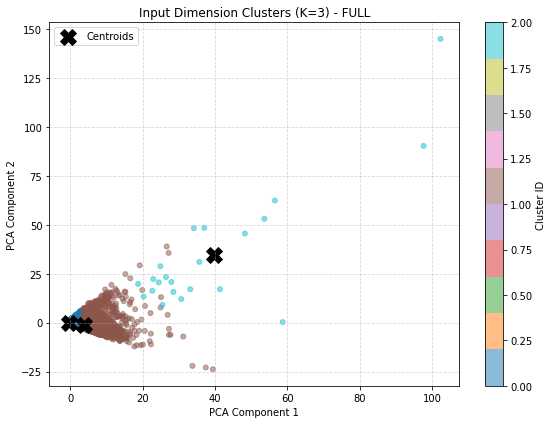


--- INPUT DIMENSION: W1 ---
Silhouette: 0.732 | Davies-Bouldin: 0.928 | Calinski-Harabasz: 39111.3

Average Raw Event Counts per Cluster (for Manual Labeling):
         event_video  event_access  event_wiki  event_discussion
cluster                                                         
0               1.98          8.52        0.33              1.44
1              20.27         68.14        1.74             17.13
2              11.22         54.58       29.61             94.98


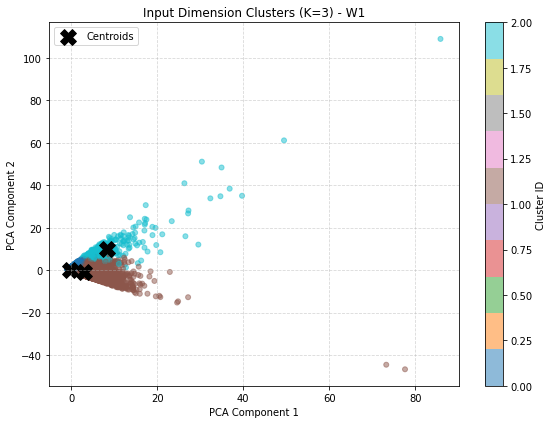


--- INPUT DIMENSION: LAST ---
Silhouette: 0.758 | Davies-Bouldin: 0.852 | Calinski-Harabasz: 38048.0

Average Raw Event Counts per Cluster (for Manual Labeling):
         event_video  event_access  event_wiki  event_discussion
cluster                                                         
0               1.96          8.33        0.24              0.99
1              11.88         49.87       33.94             82.49
2              22.26         71.67        0.92             12.32


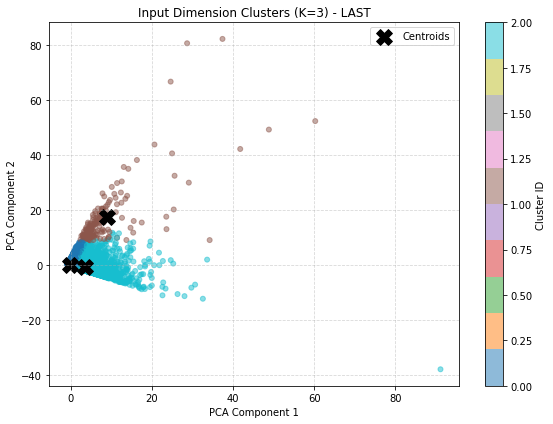

In [18]:
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Set up NVIDIA A40 GPU device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing acceleration on: {device}")

input_cols = ['event_video', 'event_access', 'event_wiki', 'event_discussion']
slices = ['full', 'w1', 'last']

# Load raw logs once to dynamically compute unscaled raw event counts per temporal slice
log_train = pd.read_csv(DATA_ROOT / "train/train/log_train.csv")
log_train['time'] = pd.to_datetime(log_train['time'])
log_train = log_train.sort_values(['enrollment_id', 'time'])

first_time = log_train.groupby('enrollment_id')['time'].transform('min')
last_time = log_train.groupby('enrollment_id')['time'].transform('max')

w1_mask = (log_train['time'] - first_time).dt.total_seconds() <= 7 * 24 * 3600
last_mask = (last_time - log_train['time']).dt.total_seconds() <= 7 * 24 * 3600

slice_dataframes = {
    'full': log_train,
    'w1': log_train[w1_mask],
    'last': log_train[last_mask]
}

for slice_name in slices:
    norm_path = TEMPORAL_COUNTS_ROOT / f"{slice_name}_norm.csv"
    if not os.path.exists(norm_path):
        continue
        
    df_norm = pd.read_csv(norm_path)
    
    # Isolate input columns and push to A40 GPU memory as PyTorch tensors
    cols_to_use = [c for c in input_cols if c in df_norm.columns]
    X_np = df_norm[cols_to_use].values
    X_tensor = torch.tensor(X_np, dtype=torch.float32, device=device)
    
    # Run K-Means (K=3)
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    clusters = kmeans.fit_predict(X_np)
    
    df_norm['cluster'] = clusters
    
    # Calculate evaluation metrics
    sil = silhouette_score(X_np, clusters)
    db = davies_bouldin_score(X_np, clusters)
    ch = calinski_harabasz_score(X_np, clusters)
    
    print(f"\n==================================================")
    print(f"--- INPUT DIMENSION: {slice_name.upper()} ---")
    print(f"==================================================")
    print(f"Silhouette: {sil:.3f} | Davies-Bouldin: {db:.3f} | Calinski-Harabasz: {ch:.1f}")
    
    # Compute average raw event counts per cluster for manual identification
    subset_df = slice_dataframes[slice_name]
    raw_counts = subset_df.groupby(['enrollment_id', 'event']).size().unstack(fill_value=0)
    raw_counts.columns = [f'event_{col}' for col in raw_counts.columns]
    raw_counts = raw_counts.reset_index()
    
    merged_raw = df_norm[['enrollment_id', 'cluster']].merge(raw_counts, on='enrollment_id', how='left').fillna(0)
    raw_cols_to_use = [c for c in input_cols if c in merged_raw.columns]
    raw_means = merged_raw.groupby('cluster')[raw_cols_to_use].mean()
    
    print("\nAverage Raw Event Counts per Cluster (for Manual Labeling):")
    print(raw_means.round(2).to_string())
    
    # PCA for fast 2D projection and visualization
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_np)
    df_norm['pca1'] = X_pca[:, 0]
    df_norm['pca2'] = X_pca[:, 1]
    
    pca_centroids = pca.transform(kmeans.cluster_centers_)
    
    # Plotting using pure Matplotlib
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        df_norm['pca1'], df_norm['pca2'], 
        c=df_norm['cluster'], 
        cmap='tab10', 
        alpha=0.5, 
        s=25
    )
    plt.scatter(
        pca_centroids[:, 0], pca_centroids[:, 1], 
        s=250, c='black', marker='X', label='Centroids'
    )
    plt.title(f'Input Dimension Clusters (K=3) - {slice_name.upper()}')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.colorbar(scatter, label='Cluster ID')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()